# Where Should Canada Invest in Innovation? Regional Business Capacity and the Shifting Face of Business R&D

**ITM 760 — Assignment 2**

## 1. Problem definition

**The challenge:** Governments, lenders, and investors have limited capital to spend on innovation, and they must decide which regions and which industries to place it. Two features of Canada's business landscape make that decision hard:

- **Regional capacity is uneven:** A handful of provinces hold most of the country's employer businesses, so a program designed around the national average can easily miss the smaller regions.
- **The industries doing business R&D are changing:** Fewer manufacturers and wholesalers report R&D activity today than a decade ago, while professional/technical services and health-related firms report more. Capital aimed at last decade's innovators may be aimed at the wrong place.

**Why it matters economically.** Business R&D is one of the main routes from ideas to productivity, skilled jobs, new products, and exports. If funding follows habit instead of evidence, Canada risks over-serving established hubs, under-serving emerging sectors and regions, and losing R&D-performing firms in industries that anchor regional economies (manufacturing is the clearest example in this data).

**Central question.** Where is Canada's innovation-related business capacity concentrated, which industries are gaining or losing R&D-performing businesses, and what does that imply for how public and private investment should be targeted?

Breakdown questions:
1. **Where?** How concentrated is the employer-business base across provinces and territories, and which regions specialise in innovation-adjacent sectors?
2. **Which sectors, and which way?** How has the number of R&D-performing businesses changed by industry from 2014 to 2023?
3. **Who spends how much?** How does average in-house R&D expenditure differ between Canadian-controlled and foreign-controlled firms, and is the gap closing?
4. **So what?** Which Big Data approaches would turn these descriptive signals into investment-grade guidance?

**Scope and limits:** The business-count data are a July 2024 snapshot at census-subdivision level, rolled up to provinces and territories. The R&D tables are annual (2014–2023) but Canada-wide. The two sets describe different dimensions of the ecosystem, so this notebook compares patterns side by side instead of claiming a matched province × industry × year panel or any causal effect. Business counts measure the *stock* of active employer businesses, not startup births, and no trade data were supplied.

## 2. Stakeholders

| Stakeholder | Role in the innovation-investment system | What they need to decide | What this notebook offers them |
|---|---|---|---|
| **Federal government** (e.g., innovation, industry, and regional development agencies) | Funds R&D tax incentives, commercialization programs, and regional development | Whether national programs reach all regions and which industries to prioritise | Regional concentration (Fig. 2), sector specialisation (Figs. 3, 5), and national R&D participation trends (Figs. 4, 6) |
| **Provincial and territorial governments** | Co-fund programs, run economic-development agencies, and shape local talent and infrastructure | How their region compares with peers and which sector to build around | Location quotients and region profiles (Fig. 5) |
| **Investors, lenders, and venture funds** | Supply growth capital and screen where deal flow is likely | Which regional ecosystems and sectors to scout | Where sector density is high relative to the national mix, and which sectors are growing in R&D participation |
| **Startups and scale-ups** | Choose where to locate, hire, and find customers and partners | Which region offers the best sector fit | Sector density by province (Figs. 3, 5) |
| **Universities and research organisations** | Supply research, talent, and technology transfer | Which industries to align partnerships and programs with | Sectors where R&D participation is rising or falling (Figs. 4, 6) |
| **Industry associations and export agencies** | Support supplier development and export readiness | Which sectors need help as R&D participation changes | Declining-participation sectors such as manufacturing and wholesale (Fig. 6) |
| **Foreign-controlled firms and their host communities** | Invest heavily per firm in Canadian R&D | Whether to keep expanding R&D in Canada | The per-firm spending gap (Fig. 1) |

Their interests partly conflict: investors favour dense, proven hubs, while governments often want to broaden participation to smaller regions. The analysis is designed to make that trade-off visible rather than hide it.

## 3. Data landscape and the 4Vs

Three Statistics Canada tables were selected because each covers a different piece of the innovation picture:

| Dataset | File | Measures | Grain | Period | Used for |
|---|---|---|---|---|---|
| **Canadian Business Counts** (Table 33-10-0766-01) | `33100766.csv` | Active businesses by NAICS and employment size | Census subdivision (rolled up to 13 provinces/territories) | July 2024 snapshot | Regional scale and sector specialisation |
| **Counts of business enterprise R&D performers** (Table 27-10-0049-01) | `27100049.csv` | Number of businesses reporting R&D, by NAICS industry | Canada | Annual, 2014–2023 | Industry trends in R&D participation |
| **Average business enterprise in-house R&D expenditures** (Table 27-10-0355-01) | `27100355.csv` | Average in-house R&D expenditure per performer, by country of control and spending bracket | Canada | Annual, 2014–2023 | Canadian- versus foreign-controlled spending |

The three tables complement each other: the first shows *where businesses are*, the second *who does R&D and how that is changing*, and the third *how much each R&D performer spends*. They cannot be joined at the province-industry level, which is a limitation addressed in the Big Data extension.

### The 4Vs applied to these data

|  | What it means here | Evidence in these data |
|---|---|---|
| **Volume** | The business-count file is by far the largest: one row per census subdivision × NAICS industry × employment-size class, repeated across thousands of municipalities. | Row, column, and memory counts are computed in the profile table below. |
| **Velocity** | Data arrive at different speeds. R&D indicators are updated annually with a lag; business counts are published as a periodic register snapshot. Neither is real-time. | One reference month for business counts versus ten annual reference years for the R&D tables. A production system would need to ingest each release and handle revisions. |
| **Variety** | Different geographies (municipality versus Canada), time grains (snapshot versus annual), measures (counts versus dollars), and classification levels (NAICS sectors versus aggregates). | Province codes had to be extracted from geographic identifiers, and overlapping NAICS aggregates and employment-size totals had to be filtered out to avoid double counting. |
| **Veracity** | Official and high quality, but with data-quality flags, suppression, overlapping hierarchies, and a metadata conflict on scale. | Status flags are summarised below. For Table 27-10-0355-01 the CSV scalar factor ("thousands") and a metadata correction note disagree, so values are shown **as published** without rescaling. |

**Measure caveats:** Business counts are employer businesses, not startups. R&D-performer counts are firms reporting R&D, not dollars. Average expenditure is a mean per performer, so it is sensitive to a few very large spenders.

In [38]:
#import necessary libraries
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [39]:
# load the dataset
sns.set_theme(style="whitegrid", context="notebook")
DATA_ROOT = Path.cwd()

def find_dataset(filename):
    matches = list(DATA_ROOT.rglob(filename))
    if len(matches) != 1:
        raise FileNotFoundError(f"Expected one {filename!r} below {DATA_ROOT}; found {len(matches)}. Run from the assignment folder.")
    return matches[0]

business = pd.read_csv(find_dataset("33100766.csv"))
research = pd.read_csv(find_dataset("27100049.csv"))
research_foreign = pd.read_csv(find_dataset("27100355.csv"))
research_foreign["REF_DATE"] = pd.to_numeric(research_foreign["REF_DATE"], errors="coerce")
research_foreign["VALUE"] = pd.to_numeric(research_foreign["VALUE"], errors="coerce")
research_foreign = research_foreign.dropna(subset=["REF_DATE", "VALUE"])

business["VALUE"] = pd.to_numeric(business["VALUE"], errors="coerce")
research["VALUE"] = pd.to_numeric(research["VALUE"], errors="coerce")
research["REF_DATE"] = pd.to_numeric(research["REF_DATE"], errors="coerce")    

### Measured data profile (4Vs in numbers)

In [40]:
# Profile each dataset: Volume (size), Velocity (time coverage), Variety (structure), Veracity (flags/missing)
def profile(df, name, date_col="REF_DATE", geo_col="GEO"):
    out = {
        "Rows": f"{len(df):,}",
        "Columns": df.shape[1],
        "Memory (MB)": f"{df.memory_usage(deep=True).sum() / 1e6:,.1f}",
        "Reference periods": f"{df[date_col].astype(str).min()} to {df[date_col].astype(str).max()} ({df[date_col].nunique()} distinct)",
        "Distinct geographies": f"{df[geo_col].nunique():,}",
        "Missing VALUE (%)": f"{df['VALUE'].isna().mean() * 100:.1f}%",
        "STATUS flags present": ", ".join(sorted(df["STATUS"].dropna().astype(str).unique())) if "STATUS" in df else "n/a",
    }
    return pd.Series(out, name=name)

profile_table = pd.concat([
    profile(business, "Business counts (33100766)"),
    profile(research, "R&D performers (27100049)"),
    profile(research_foreign, "Avg R&D expenditure (27100355)"),
], axis=1)
display(profile_table)

,Business counts (33100766),R&D performers (27100049),Avg R&D expenditure (27100355)
Rows,"1,050,033",756,240
Columns,16,15,16
Memory (MB),654.8,0.4,0.1
Reference periods,2024-07 to 2024-07 (1 distinct),2014 to 2023 (10 distinct),2014 to 2023 (10 distinct)
Distinct geographies,"3,175",1,1
Missing VALUE (%),0.0%,0.0%,0.0%
STATUS flags present,,A,"A, B, C, D, E"


In [41]:
# Total expenditure-group row is the average across all R&D expenditure brackets.
total_group = "Total research and development expenditure groups"
rd_control = research_foreign.loc[
    research_foreign["GEO"].eq("Canada")
    & research_foreign["Research and development expenditure groups"].eq(total_group)
    & research_foreign["Country of control"].isin(["Canada", "Foreign"])
].copy()

## 4. Exploratory analysis

### 4.1 National R&D spending: Canadian- versus foreign-controlled firms

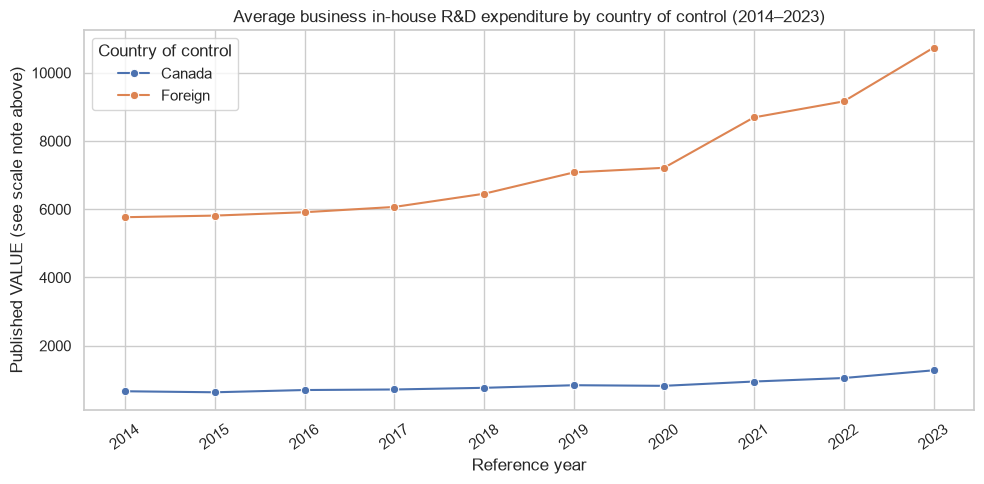

,VALUE,UOM,SCALAR_FACTOR,STATUS
Country of control,,,,
Canada,"1,279",Dollars,thousands,B
Foreign,"10,736",Dollars,thousands,B


Reference years: 2014 to 2023
Status flags for these rows: A, B, C


In [ ]:
# Figure 1: Average business in-house R&D expenditure by country of control (2014–2023)
fig, ax = plt.subplots(figsize=(10, 5))
sns.lineplot(data=rd_control, x="REF_DATE", y="VALUE", hue="Country of control", marker="o", ax=ax)
ax.set(title="Figure 1:Average business in-house R&D expenditure by country of control (2014–2023)", xlabel="Reference year", ylabel="Published VALUE (see scale note above)")
ax.set_xticks(sorted(rd_control["REF_DATE"].unique()))
ax.tick_params(axis="x", rotation=35)
ax.legend(title="Country of control")
plt.tight_layout()
plt.show()

latest_year = int(rd_control["REF_DATE"].max())
latest_rd = rd_control.loc[rd_control["REF_DATE"].eq(latest_year), ["Country of control", "VALUE", "UOM", "SCALAR_FACTOR", "STATUS"]].set_index("Country of control")
display(latest_rd.style.format({"VALUE": "{:,.0f}"}))
print("Reference years:", int(rd_control["REF_DATE"].min()), "to", latest_year)
print("Status flags for these rows:", ", ".join(sorted(rd_control["STATUS"].dropna().unique())))

**Interpretation (Figure 1):** Foreign-controlled R&D performers spend far more per firm than Canadian-controlled ones: about 10,736 versus 1,279 in 2023 (published values, shown as thousands of dollars in the CSV), roughly **8.4 times** as much. The gap is wide but not widening in relative terms: it was about 8.7 times in 2014 (5,767 versus 665), and Canadian-controlled firms grew slightly faster in percentage terms (about +92% versus +86%). The *absolute* gap grew sharply because the foreign-controlled base is so much larger.

**Why it matters:** Canadian-controlled firms are the typical homegrown startups and scale-ups. Their average R&D spend per firm is a small fraction of what foreign-controlled firms invest, which points to a **scale-up gap** rather than a participation gap. Programs aimed at helping Canadian firms grow their R&D budgets, not only start R&D, may therefore matter. These are means per performer, so a few very large spenders can pull them up; the data do not show distributions.

### 4.2 Regional business scale (July 2024)

In [43]:
province_names = {"10": "Newfoundland and Labrador", "11": "Prince Edward Island", "12": "Nova Scotia", "13": "New Brunswick", "24": "Quebec", "35": "Ontario", "46": "Manitoba", "47": "Saskatchewan", "48": "Alberta", "59": "British Columbia", "60": "Yukon", "61": "Northwest Territories", "62": "Nunavut"}
business["province_code"] = business["DGUID"].astype("string").str.extract(r"2021A0005(\d{2})", expand=False)
business["Province/territory"] = business["province_code"].map(province_names)
business = business.dropna(subset=["VALUE", "Province/territory"])
industry = "North American Industry Classification System (NAICS)"
employee_total = "Total, with employees"
all_industries = "Total, all industries [1]"

# Sum census-subdivision totals, not overlapping CMA rows or employment-size groups.
province_totals = (business.loc[business["Employment size"].eq(employee_total) & business[industry].eq(all_industries)].groupby("Province/territory", as_index=False)["VALUE"].sum().rename(columns={"VALUE": "Active businesses with employees"}).sort_values("Active businesses with employees", ascending=False))
research = research.dropna(subset=["VALUE", "REF_DATE"])
print(f"Business-count reference period(s): {', '.join(sorted(business['REF_DATE'].astype(str).unique()))}")
print(f"Province/territory totals: {province_totals['Province/territory'].nunique()} of 13")
print(f"R&D-performer geography and years: {', '.join(research['GEO'].dropna().unique())}, {int(research['REF_DATE'].min())}–{int(research['REF_DATE'].max())}")
display(province_totals.reset_index(drop=True).style.format({"Active businesses with employees": "{:,.0f}"}))


Business-count reference period(s): 2024-07
Province/territory totals: 13 of 13
R&D-performer geography and years: Canada, 2014–2023


,Province/territory,Active businesses with employees
0,Ontario,"508,761"
1,Quebec,"277,853"
2,British Columbia,"216,249"
3,Alberta,"177,431"
4,Manitoba,"43,632"
5,Saskatchewan,"42,019"
6,Nova Scotia,"32,664"
7,New Brunswick,"26,261"
8,Newfoundland and Labrador,"18,308"
9,Prince Edward Island,"6,832"


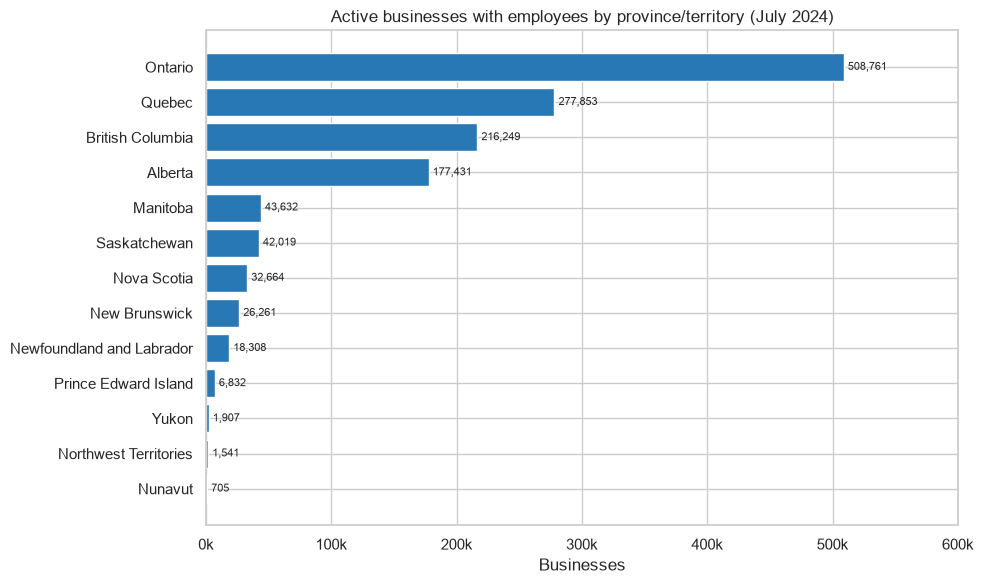

In [ ]:
# Figure 2: regional business scale.
plot_totals = province_totals.sort_values("Active businesses with employees")
fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.barh(plot_totals["Province/territory"], plot_totals["Active businesses with employees"], color="#2878B5")
ax.bar_label(bars, labels=[f"{v:,.0f}" for v in plot_totals["Active businesses with employees"]], padding=3, fontsize=8)
ax.set(title="Figure 2: Active businesses with employees by province/territory (July 2024)", xlabel="Businesses", ylabel="")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x/1_000:,.0f}k"))
ax.set_xlim(0, plot_totals["Active businesses with employees"].max() * 1.18)
plt.tight_layout()
plt.show()

**Interpretation (Figure 2):** The employer-business base is highly concentrated. Ontario alone has about **38%** of all employer businesses in the snapshot (508,761). Ontario, Quebec, and British Columbia together hold roughly **74%**, and adding Alberta brings it to about **87%**. The four Prairie, Atlantic, and territorial groups below them are an order of magnitude smaller (Manitoba and Saskatchewan each around 42,000; Nunavut about 700).

**Why it matters:** Any program or investment screen based on raw counts will favour the four large provinces. Smaller provinces and the territories need a different yardstick, such as *specialisation* (next section) rather than size, if they are to be assessed fairly.

### 4.3 Sector specialisation across regions

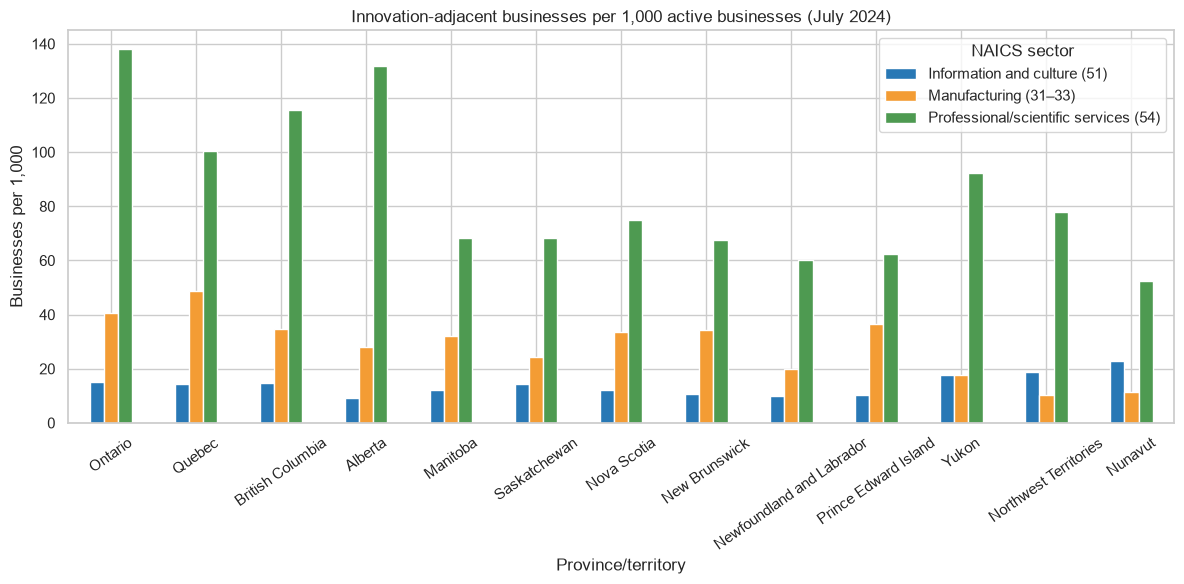

In [ ]:
# Figure 3: sector specialization normalized by the total business base.
sectors = {"Professional, scientific and technical services [54]": "Professional/scientific services (54)", "Information and cultural industries [51]": "Information and culture (51)", "Manufacturing [31-33]": "Manufacturing (31–33)"}
sector_rows = business.loc[business["Employment size"].eq(employee_total) & business[industry].isin(sectors)].copy()
sector_rows["Sector"] = sector_rows[industry].map(sectors)
sector_counts = sector_rows.groupby(["Province/territory", "Sector"], as_index=False)["VALUE"].sum()
sector_mix = sector_counts.merge(province_totals, on="Province/territory", how="inner")
sector_mix["Businesses per 1,000"] = sector_mix["VALUE"] / sector_mix["Active businesses with employees"] * 1_000
sector_pivot = sector_mix.pivot(index="Province/territory", columns="Sector", values="Businesses per 1,000").reindex(province_totals["Province/territory"])
ax = sector_pivot.plot(kind="bar", figsize=(12, 6), color=["#2878B5", "#F39C34", "#4E9A51"])
ax.set(title="Figure 3: Innovation-adjacent businesses per 1,000 active businesses (July 2024)", xlabel="Province/territory", ylabel="Businesses per 1,000")
ax.tick_params(axis="x", rotation=35)
ax.legend(title="NAICS sector", frameon=True)
plt.tight_layout()
plt.show()

**Interpretation (Figure 3):** Normalising by each region's total business base removes the size effect and shows *profile* differences. Professional/scientific/technical services is the densest of the three sectors everywhere, led by **Ontario (about 138 per 1,000) and Alberta (about 132)**, with British Columbia (about 115) and Quebec (about 100) next. **Quebec has the highest manufacturing density (about 49 per 1,000)**, ahead of Ontario (about 40). Among the territories, Yukon has a relatively high professional-services share, and Nunavut and the Northwest Territories show the highest information-and-culture shares.

The territories have very small business bases (between about 700 and 1,900 businesses), so their per-1,000 ratios move a lot with a handful of firms. Alberta's strong professional-services density, given a smaller business base than Quebec or British Columbia, is the most striking result: it suggests a services-based innovation profile that is not simply a function of size.

The next two figures extend this view with a standardised specialisation measure (location quotient) and with a clustering of regions.

### 4.4 Which industries are gaining or losing R&D performers (2014–2023)

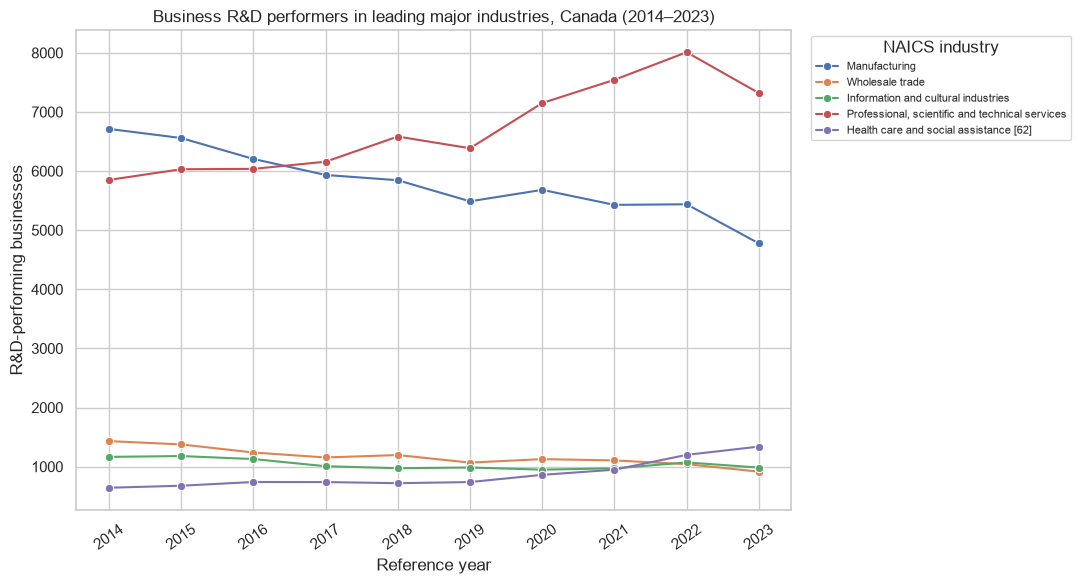

REF_DATE,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,"Change, first to latest (%)"
North American Industry Classification System (NAICS),,,,,,,,,,,
"Professional, scientific and technical services",5850,6031,6037,6158,6584,6386,7151,7544,8010,7319,+25.1%
Manufacturing,6713,6559,6205,5934,5845,5488,5682,5428,5438,4776,-28.9%
Health care and social assistance [62],643,677,740,739,720,739,861,948,1199,1339,+108.2%
Information and cultural industries,1165,1179,1128,1007,973,985,949,971,1071,984,-15.5%
Wholesale trade,1432,1376,1239,1155,1196,1068,1127,1105,1042,915,-36.1%


Largest business base: Ontario (508,761)
R&D status flags in the supplied table: A


In [ ]:
# Figure 4: national R&D-performer trend for major industries, excluding overlapping aggregates.
major_industries = ["Agriculture, forestry, fishing and hunting", "Mining, quarrying, and oil and gas extraction", "Utilities", "Construction [23]", "Manufacturing", "Wholesale trade", "Retail trade [44-45]", "Transportation and warehousing [48-49]", "Information and cultural industries", "Finance and insurance [52]", "Real estate and rental and leasing [53]", "Professional, scientific and technical services", "Management of companies and enterprises [55]", "Administrative and support, waste management and remediation services [56]", "Educational services [61]", "Health care and social assistance [62]", "All other services [71, 72, 81]"]
national = research.loc[research["GEO"].eq("Canada") & research[industry].isin(major_industries)].copy()
latest_year = int(national["REF_DATE"].max())
top_industries = national.loc[national["REF_DATE"].eq(latest_year)].nlargest(5, "VALUE")[industry].tolist()
trend = national.loc[national[industry].isin(top_industries)]
fig, ax = plt.subplots(figsize=(11, 6))
sns.lineplot(data=trend, x="REF_DATE", y="VALUE", hue=industry, marker="o", ax=ax)
ax.set(title="Figure 4: Business R&D performers in leading major industries, Canada (2014–2023)", xlabel="Reference year", ylabel="R&D-performing businesses")
ax.set_xticks(sorted(trend["REF_DATE"].unique()))
ax.tick_params(axis="x", rotation=35)
ax.legend(title="NAICS industry", bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()
trend_summary = trend.pivot(index=industry, columns="REF_DATE", values="VALUE").reindex(top_industries)
trend_summary["Change, first to latest (%)"] = (trend_summary[latest_year] / trend_summary[trend_summary.columns[0]] - 1) * 100
display(trend_summary.style.format("{:,.0f}").format({"Change, first to latest (%)": "{:+.1f}%"}))
print("Largest business base:", province_totals.iloc[0]["Province/territory"], f"({province_totals.iloc[0]['Active businesses with employees']:,.0f})")
print("R&D status flags in the supplied table:", ", ".join(sorted(research["STATUS"].dropna().unique())))

**Interpretation (Figure 4):** Among the five industries with the most R&D performers in 2023, the trends diverge:

| Industry | 2014 | 2023 | Change |
|---|---|---|---|
| Professional, scientific and technical services | 5,850 | 7,319 | **+25.1%** (peaked at 8,010 in 2022) |
| Manufacturing | 6,713 | 4,776 | **−28.9%** (declined in nearly every year) |
| Health care and social assistance | 643 | 1,339 | **+108.2%** (from a small base) |
| Information and cultural industries | 1,165 | 984 | **−15.5%** |
| Wholesale trade | 1,432 | 915 | **−36.1%** |

**Why it matters:** Manufacturing was the single largest group of R&D performers in 2014 and had fallen behind professional services by 2020. Together with Figure 3, where Quebec and Ontario have the highest manufacturing densities, this suggests that **R&D participation is eroding in the industry that anchors those regional economies**. Professional services dropped about 9% in 2023 after peaking in 2022, so even the growth sector is not a straight line.

### 4.5 Location quotients and a first clustering of regions

A **location quotient (LQ)** is a region's share of a sector divided by the national share. LQ above 1 means the region is more specialised in that sector than Canada overall. This puts large and small regions on the same footing. As a first Big Data technique, the notebook then applies **k-means clustering** to standardised region features (scale plus the three specialisation measures) to group regions with similar profiles. 

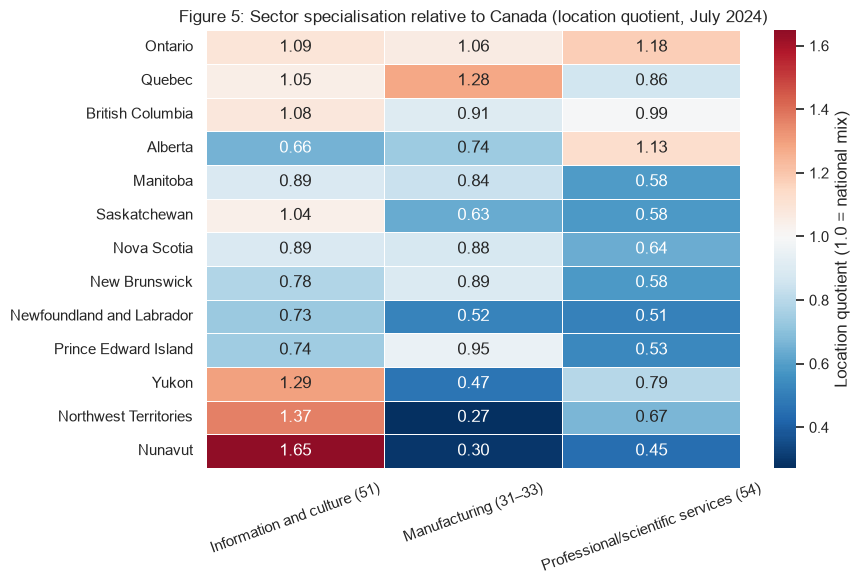

,Regions,Avg log10 businesses
Cluster,,
0,"Manitoba, Saskatchewan, Nova Scotia, New Brunswick, Newfoundland and Labrador, Prince Edward Island",4.38
1,"Yukon, Northwest Territories, Nunavut",3.11
2,"Ontario, Quebec, British Columbia, Alberta",5.43


In [47]:
# Figure 5: location quotients (specialisation vs. the national mix) + illustrative k-means region profiles
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

national_per_1000 = (sector_counts.groupby("Sector")["VALUE"].sum() / province_totals["Active businesses with employees"].sum() * 1_000)
sector_mix["Location quotient"] = sector_mix["Businesses per 1,000"] / sector_mix["Sector"].map(national_per_1000)
lq = sector_mix.pivot(index="Province/territory", columns="Sector", values="Location quotient").reindex(province_totals["Province/territory"])

fig, ax = plt.subplots(figsize=(9, 6))
sns.heatmap(lq, annot=True, fmt=".2f", cmap="RdBu_r", center=1.0, linewidths=0.5, cbar_kws={"label": "Location quotient (1.0 = national mix)"}, ax=ax)
ax.set(title="Figure 5: Sector specialisation relative to Canada (location quotient, July 2024)", xlabel="", ylabel="")
ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

# Illustrative clustering: log(scale) + three LQs, standardised
features = lq.copy()
features["log10 businesses"] = np.log10(province_totals.set_index("Province/territory")["Active businesses with employees"])
X = StandardScaler().fit_transform(features)
km = KMeans(n_clusters=3, n_init=10, random_state=42).fit(X)
features["Cluster"] = km.labels_
cluster_summary = (features.reset_index().groupby("Cluster")
                   .agg(Regions=("Province/territory", lambda s: ", ".join(s)),
                        **{"Avg log10 businesses": ("log10 businesses", "mean")}))
display(cluster_summary.style.format({"Avg log10 businesses": "{:.2f}"}))

**Interpretation (Figure 5):** The heatmap restates Figure 3 on a common scale: blue cells (below 1.0) are under-specialised and red cells (above 1.0) are over-specialised relative to Canada. It highlights the profile differences hidden by raw counts. For example, Alberta and Ontario sit above the national mix in professional services, Quebec stands out in manufacturing, and several territories show high information-and-culture quotients driven by very small bases.

The clustering table groups regions by a combined profile of scale and specialisation. Read the grouping as a **demonstration of the method**: it shows how decision-makers could identify "peer regions" for benchmarking and program design (for instance, large diversified hubs versus small resource-based or northern economies). A real application would use more regions (such as census metropolitan areas), more sectors, and richer indicators, and would test how stable the groups are.

### 4.6 Comparable trends and a simple forecast baseline

Raw counts differ by an order of magnitude across industries, so the lines in Figure 4 are hard to compare. Indexing each industry to 100 in 2014 shows relative momentum. A straight-line trend fitted to 2014–2023 is projected forward as a deliberately **naive baseline** that a richer forecasting model must beat.

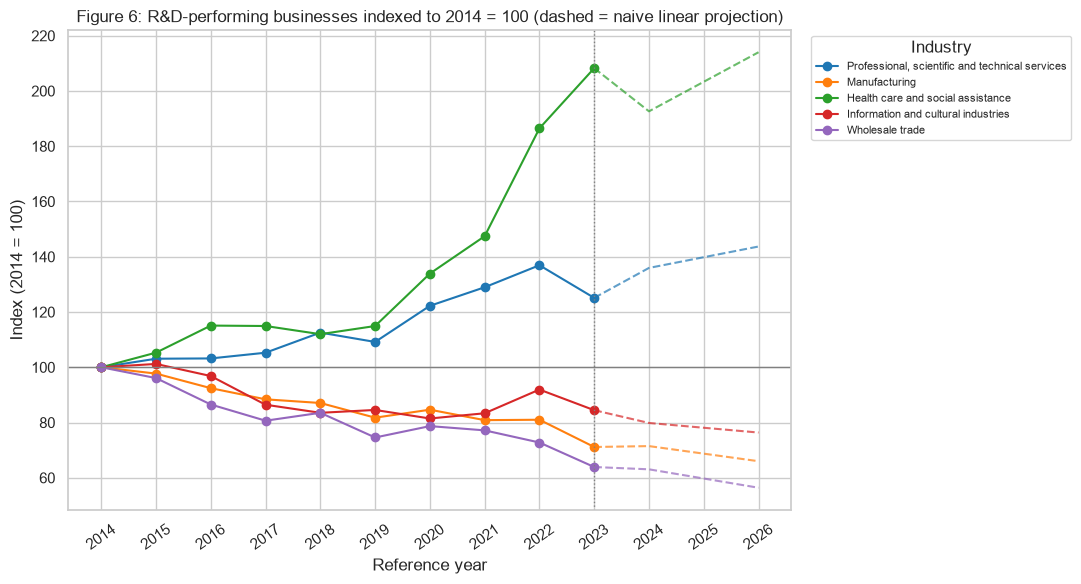

,2023 actual,2024,2025,2026
"Professional, scientific and technical services","7,319","7,953","8,180","8,407"
Manufacturing,"4,776","4,798","4,614","4,431"
Health care and social assistance,"1,339","1,239","1,307","1,376"
Information and cultural industries,984,930,910,890
Wholesale trade,915,903,855,808


In [48]:
# Figure 6: indexed trends (2014 = 100) with a naive linear-trend projection to 2026
import re
wide = trend.pivot(index="REF_DATE", columns=industry, values="VALUE").reindex(columns=top_industries)
wide.columns = [re.sub(r"\s*\[.*?\]", "", c) for c in wide.columns]
indexed = wide / wide.iloc[0] * 100

future_years = np.arange(int(wide.index.max()) + 1, int(wide.index.max()) + 4)
fig, ax = plt.subplots(figsize=(11, 6))
palette = sns.color_palette("tab10", n_colors=len(indexed.columns))
projections = {}
for color, col in zip(palette, indexed.columns):
    ax.plot(indexed.index, indexed[col], marker="o", color=color, label=col)
    slope, intercept = np.polyfit(wide.index.astype(float), wide[col].values, 1)
    proj = slope * future_years + intercept
    projections[col] = proj
    ax.plot(np.r_[wide.index[-1], future_years], np.r_[indexed[col].iloc[-1], proj / wide[col].iloc[0] * 100],
            linestyle="--", color=color, alpha=0.7)
ax.axhline(100, color="grey", lw=1)
ax.axvline(wide.index.max(), color="grey", lw=1, linestyle=":")
ax.set(title="Figure 6: R&D-performing businesses indexed to 2014 = 100 (dashed = naive linear projection)",
       xlabel="Reference year", ylabel="Index (2014 = 100)")
ax.set_xticks(list(wide.index) + list(future_years)); ax.tick_params(axis="x", rotation=35)
ax.legend(title="Industry", bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

proj_table = pd.DataFrame(projections, index=future_years).T.round(0)
proj_table.insert(0, f"{int(wide.index.max())} actual", wide.iloc[-1].round(0))
display(proj_table.style.format("{:,.0f}"))

**Interpretation (Figure 6):** Indexing makes momentum comparable. Health care and social assistance more than doubled (index above 200) even though it is small in absolute terms, while wholesale trade, manufacturing, and information and culture all sit below 100. Professional services is above 100 but has turned down since 2022.

The dashed lines extend each industry's 10-year linear trend three years forward. They are a **baseline, not a prediction**: they ignore the pandemic-era jump and the 2022–2023 reversal, carry no uncertainty bands, and use only ten points. The point of showing them is to set up the forecasting approach proposed below, where any more sophisticated model should be judged against this simple benchmark.

In [49]:
# Key numbers quoted in the insights below, computed from the data so the text can be checked
tot = province_totals["Active businesses with employees"].sum()
top3 = province_totals.head(3)["Active businesses with employees"].sum()
top4 = province_totals.head(4)["Active businesses with employees"].sum()
print(f"Ontario share of employer businesses: {province_totals.iloc[0, 1] / tot:.1%}")
print(f"Top 3 provinces: {top3 / tot:.1%} | Top 4: {top4 / tot:.1%}")
for yr in (2014, int(rd_control['REF_DATE'].max())):
    r = rd_control[rd_control["REF_DATE"].eq(yr)].set_index("Country of control")["VALUE"]
    print(f"{yr}: foreign / Canadian-controlled average R&D = {r['Foreign'] / r['Canada']:.1f}x")
g = rd_control.pivot(index="REF_DATE", columns="Country of control", values="VALUE")
print("Growth 2014 to latest:", ((g.iloc[-1] / g.iloc[0] - 1) * 100).round(0).to_dict())
print(sector_mix.pivot(index="Province/territory", columns="Sector", values="Businesses per 1,000").round(0).loc[["Ontario", "Alberta", "British Columbia", "Quebec"]])

Ontario share of employer businesses: 37.6%
Top 3 provinces: 74.1% | Top 4: 87.2%
2014: foreign / Canadian-controlled average R&D = 8.7x
2023: foreign / Canadian-controlled average R&D = 8.4x
Growth 2014 to latest: {'Canada': 92.0, 'Foreign': 86.0}
Sector              Information and culture (51)  Manufacturing (31–33)  \
Province/territory                                                        
Ontario                                     15.0                   40.0   
Alberta                                      9.0                   28.0   
British Columbia                            15.0                   35.0   
Quebec                                      14.0                   49.0   

Sector              Professional/scientific services (54)  
Province/territory                                         
Ontario                                             138.0  
Alberta                                             132.0  
British Columbia                                    116.0  


## 5. Translating the analysis into Big Data approaches

The exploratory results are descriptive. Turning them into investment guidance requires methods that scale to larger and more detailed data. The table links each approach to a gap found above.

| Approach | Problem it addresses | Inputs | Output for decision-makers | Why it is suited (and its main risk) |
|---|---|---|---|---|
| **Clustering** (k-means, hierarchical, or Gaussian mixture) on standardised region × sector features | Raw counts hide "peer regions" (Fig. 5) | Specialisation (LQs), scale, R&D intensity, talent, export measures, at census-metropolitan-area level | Region archetypes (e.g., diversified hub, resource-based, emerging services) so programs can be tailored by type | Unsupervised, so it needs no labels and scales to thousands of areas. Risk: results depend on feature choice and k, so stability must be tested. |
| **Time-series and hierarchical forecasting** (ETS/ARIMA, with reconciliation across industry levels) | Participation is falling in some industries and rising in others, and the naive trend (Fig. 6) ignores shocks | Annual R&D-performer counts and expenditures by industry, ideally by province | Forecasts with prediction intervals to anticipate shortfalls in manufacturing or growth in health | Respects the industry hierarchy and quantifies uncertainty. Risk: only about 10 annual points per series, so models must stay simple and be validated by rolling-origin tests. |
| **Panel regression / difference-in-differences with matched regions** | "Did a program work?" cannot be answered from snapshots | A province × industry × year panel with program-participation flags | Estimated program effects with caveats | Moves from description toward evaluation. Risk: requires parallel-trends and comparability assumptions that must be tested. |
| **Anomaly detection and concentration metrics** (e.g., HHI, Gini) | A few very large spenders can distort averages (Fig. 1) | Firm-level or bracket-level expenditure distributions | Flags for concentration risk and unusual regions or years | Complements averages with distributional views. Risk: firm-level data are confidential, so access is restricted. |
| **Record linkage and entity resolution** | Datasets use different geographies, NAICS levels, and identifiers | Business register, R&D survey, patents, trade, labour-market data | A privacy-aware, linked province–industry–year panel | The prerequisite for all methods above. Risk: privacy and disclosure rules. |

**Architecture:** At national scale, a scheduled batch pipeline would ingest each Statistics Canada release into a columnar store (such as Parquet), apply NAICS and geography concordances, track suppression flags and revisions, and refresh a dashboard. A distributed engine such as Spark would only be needed once firm-level or multi-decade data are used.

## 6. Business insights and value for Canadian economic development

|  | Finding (from this analysis) | Implication for Canada's economic development | Suggested action | Metric to monitor |
|---|---|---|---|---|
| 1 | **Concentration.** Ontario, Quebec, and BC hold about 74% of employer businesses; Ontario alone about 38%. | Capital allocated by firm count will flow mostly to three provinces and widen regional gaps. | Pair size-based screening with specialisation-based screening so smaller regions are assessed on their own strengths. | Share of program funding versus share of business base, by region |
| 2 | **Alberta's services profile.** Alberta's professional-services density (about 132 per 1,000) is second only to Ontario's, despite a smaller business base. | Alberta has a services-based innovation base that could support economic diversification. | Explore applied-research and commercialisation programs that build on this base; follow up with local data before committing funds. | Professional-services firm growth and R&D-performer counts in Alberta |
| 3 | **Manufacturing erosion.** R&D-performing manufacturers fell 29% (6,713 to 4,776) and manufacturing is most dense in Quebec (about 49 per 1,000) and Ontario. | R&D participation is shrinking in the industry that anchors these regional economies and many supplier networks. | Prioritise advanced-manufacturing adoption, supplier development, and technology-transfer support in Quebec and Ontario. | Count of manufacturing R&D performers; share of manufacturers doing R&D |
| 4 | **Services and health momentum.** Professional services rose 25% (peak 2022) and health care and social assistance rose 108% from a small base. | Emerging R&D participation exists outside traditional industries. Health is small but fast-moving. | Track health-sector R&D closely; align university and hospital partnerships. Watch whether the 2023 services dip persists. | Annual change in R&D performers by industry |
| 5 | **Scale-up gap.** Foreign-controlled R&D performers spend about 8.4 times more per firm than Canadian-controlled ones, and the ratio has barely moved since 2014. | The issue is less about starting R&D than about growing Canadian firms' R&D budgets and retaining IP and talent. | Favour scale-up supports (growth financing, procurement, IP retention) over entry-level grants alone. | Average R&D spend per Canadian-controlled performer; ratio to foreign-controlled |
| 6 | **Small regions need their own lens.** Territories and small provinces have tiny business bases, so ratios are volatile. | Standard benchmarks can mislead for the North and Atlantic Canada. | Use multi-year averages and peer-region comparisons (clustering) for small regions. | Stability of rankings across years |

**What decision-makers should and should not conclude.** The results justify *where to look next* and *which questions to ask*, such as follow-up ecosystem assessments in specific regions and sectors. They do not justify allocating funds on their own: the business counts are a single snapshot, the R&D series are national, and none of these measures captures startup formation, productivity, wages, or causal program effects. Before allocation, the data should be combined with startup birth and survival, workforce, wages, trade, and funding data.

## 7. Limitations and next steps

- **No provincial R&D data.** The supplied R&D tables are Canada-only, so provincial R&D participation and spending cannot be compared, and regional and R&D patterns cannot be correlated.
- **Snapshot business data.** The business-count file covers one month (July 2024), so regional change over time cannot be measured; active employer businesses are a stock, not startup births.
- **No trade data.** Export-related recommendations would need a linked trade table.
- **Counts versus dollars.** R&D-performer counts show participation, not investment size; averages per performer can be driven by a few large firms.
- **Scale ambiguity in Table 27-10-0355-01.** The CSV's scalar factor and the metadata note conflict, so values are shown as published; absolute units should be confirmed with Statistics Canada before being quoted in dollars.
- **Prototype methods.** The clustering uses 13 regions and the forecast is a naive linear baseline; both demonstrate approach, not final results.
- **Correlation, not causation.** Nothing here establishes that any policy caused any trend.

**Next steps:** add census-metropolitan-area granularity, a province-level R&D series, startup birth/survival data, and trade flows; link them into a privacy-aware panel; and replace the prototype methods with validated clustering and forecasting models with uncertainty bands.

## Data sources

- Statistics Canada, [Canadian Business Counts, with employees, by employment size and NAICS](https://www150.statcan.gc.ca/t1/tbl1/en/tv.action?pid=3310076601) (Table 33-10-0766-01).
- Statistics Canada, [Counts of business enterprise R&D performers by industry group based on NAICS](https://www150.statcan.gc.ca/t1/tbl1/en/tv.action?pid=2710004901) (Table 27-10-0049-01).
- Statistics Canada, [Average business enterprise in-house R&D expenditures by country of control and expenditure group](https://www150.statcan.gc.ca/t1/tbl1/en/tv.action?pid=2710035501) (Table 27-10-0355-01).